### CM3015 End-of-year coursework

Name: Justin Ng Kwan Wei  SIM ID: 10261713  UP UD: 240662170


# Student Placement Prediction Dataset


This notebook demonstrates the **Universal ML Workflow** applied to a binary classification problem from a student placement dataset [1].



---

## Dataset Overview

| Attribute | Description |
|-----------|-------------|
| **Source** | [Kaggle Student Placement Dataset](https://www.kaggle.com/datasets/sonalshinde123/student-placement-dataset) |
| **Problem Type** | Binary-Class Classification (2 classes) |
| **Data Balance** | Mild imbalance (~63.8% Not Placed, ~36.2% Placed) |
| **Data Type** | Structured tabular data (student academic and skill features) |
| **Input Features** | CGPA, Internships, Projects, Coding Skills, Communication Skills, Aptitude Score, Soft Skills Rating, Certifications, Backlogs, Degree*, Branch* |
| **Output** | Placement Status: Placed or Not Placed |
| **Imbalance Handling** | None (mild imbalance) |

(*) The selected datatypes are One-Hot Encoded to allow model development.

---

## Technique Scope

This notebook uses only techniques from **Chapters 1–4** of *Deep Learning with Python* (Chollet, 2021). This means:

| Technique | Status | Rationale |
|-----------|--------|-----------|
| **Dense layers (MLP/DNN)** | ✓ Used | Core building block (Ch. 3-4) |
| **Dropout** | ✓ Used | Regularisation technique (Ch. 4) |
| **L2 regularisation** |✗ Not used  | Weight penalty (Ch. 4) |
| **Early stopping** | ✗ Not used | Introduced in Ch. 7 |
| **CNN** | ✗ Not used | Introduced in Ch. 8 |
| **RNN/LSTM** | ✗ Not used | Introduced in Ch. 10 |



---

## 1. Defining the Problem and Assembling a Dataset

The first step in my machine learning project is to define the problem and understand its contents.

**Problem Statement:** Given a student's academic profile, academic performance, and technical skills, predict whether the student will successfully secure a campus placement (Placed or Not Placed).

**Why this matters:** Predicting placement outcomes allows institutions and students to better understand which academic and skill-based factors contribute to campus placement success. Such insights can help identify areas that require improvement and guide students in developing the competencies needed to increase their likelihood of securing placement on campus. 

**Why this dataset?:** Real-world student placement data can be sensitive, as it involves personal academic records, skill assessments, and employment outcomes. Collecting such data may raise privacy concerns, and students may underreport or misrepresent certain attributes, leading to biased or unreliable datasets. Therefore, using a synthetically generated dataset is appropriate in this context. Although the data is synthetic, it is constructed with strict logical constraints that simulate realistic relationships between academic performance, skills, and placement outcomes. This allows for meaningful modelling and experimentation while avoiding ethical and privacy concerns associated with real student data.

## 2. Choosing a Measure for Success

### Metric Selection Based on Class Imbalance

| Imbalance Ratio | Classification | Primary Metric | Rationale |
|-----------------|----------------|----------------|----------|
| ≤ 1.5:1 | Balanced | **Accuracy** | Classes roughly equal |
| 1.5:1 – 3:1 | Mild Imbalance | **Accuracy** | Majority class < 75% |
| > 3:1 | Moderate/Severe | **F1-Score** | Accuracy becomes misleading |


The choice of evaluation metric depends on the class distribution in the dataset [2]. The training dataset contains 45,000 instances, with 28,688 labelled as “Not Placed” and 16,312 labelled as “Placed”. This corresponds to an imbalance ratio of approximately 1.76:1 (Not Placed to Placed), or 63.8% and 36.2% of the dataset respectively.

This level of imbalance is relatively moderate compared to severely imbalanced domains where the minority class may represent only a small fraction of the dataset [3]. As the imbalance is not extreme, accuracy can still provide meaningful insight into overall model performance. However, additional metrics such as precision and recall are also considered to ensure that the classifier performs adequately on both classes.



## 3. Deciding on an Evaluation Protocol


### Hold-Out vs K-Fold Cross-Validation

The choice between hold-out and K-fold depends on dataset size and computational cost [4]:

| Dataset Size | Recommended Method | Rationale |
|--------------|-------------------|----------|
| < 1,000 | K-Fold (K=5 or 10) | High variance with small hold-out sets |
| 1,000 – 10,000 | K-Fold or Hold-Out | Either works; K-fold more robust |
| > 10,000 | Hold-Out | Sufficient data; K-fold computationally expensive |
| Deep Learning | Hold-Out (preferred) | Training cost prohibitive for K iterations |


### Data Split Strategy (This Notebook)

```
Original Data (50,000 samples) → Hold-Out Selected
├── Test Set (10%)(5,000 samples) - Final evaluation only
└── Training Pool (90%) (45,000 samples)
    ├── Training Set (72%) (36,000 samples) - Model training
    └── Validation Set (18%) (9,000 samples) - Hyperparameter tuning
```


Given the dataset size of 50,000 samples and the computational cost associated with deep learning models, a hold-out validation strategy is selected over K-fold cross-validation. For large datasets (>10,000 samples), hold-out validation is generally sufficient and computationally more efficient, especially when training neural networks [4] [5].

The provided dataset is already divided into:

    Training set: 45,000 samples

    Test set: 5,000 samples (10%) — reserved strictly for final evaluation

To further support model development, the training set is split into:

    Training subset: 36,000 samples (72% of total dataset)

    Validation subset: 9,000 samples (18% of total dataset)

The split will be performed using stratified sampling to maintain the original class distribution of “Placed” and “Not Placed” instances.

The training subset is used to learn model parameters, the validation subset is used for hyperparameter tuning and early stopping, and the test set is used only once to obtain an unbiased estimate of generalisation performance.

## 4. Preparing the Data

### 4.1 Importing the libaries and setting random seed

We first import our necessary libaries and set a randoms seed. We will use seed 42 for this notebook.

In [ ]:
pip install numpy pandas matplotlib scikit-learn tensorflow jupyterlab

In [1]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

import kagglehub
tf.random.set_seed(42)
SEED = 42

C:\Users\kwjus\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 4.2.1 Loading the dataset 

Lets download the dataset from Kaggle and then examine its structure.

In [2]:
# Code to download the dataset from kaggle.
path = kagglehub.dataset_download("sonalshinde123/student-placement-dataset")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\kwjus\.cache\kagglehub\datasets\sonalshinde123\student-placement-dataset\versions\1


Now that we have downloaded the dataset, we will move the contents to our current folder.

In [3]:
source_folder = path   # folder containing the files
target_folder = os.getcwd()       # current directory
for item in os.listdir(source_folder):
    src = os.path.join(source_folder, item)
    dst = os.path.join(target_folder, item)
    shutil.move(src, dst)
print("Contents moved into current folder:", target_folder)

Contents moved into current folder: C:\Users\kwjus\OneDrive\Desktop\SIM University October 2024\Term 3\Machine learning\Machine Learning Final\Folder for coursework


### 4.2.2 Exploring the dataset

Lets read the csv files from the dataset then examine its structure.

In [4]:
trainDataset = pd.read_csv("Student Placement Dataset/train.csv")
testDataset = pd.read_csv("Student Placement Dataset/test.csv")
print("Train dataset has been saved inside trainDataset")
print("Test dataset has been saved inside testDataset")

Train dataset has been saved inside trainDataset
Test dataset has been saved inside testDataset


#### Dataset previews
--- 

In [5]:
trainDataset

,Student_ID,Age,Gender,Degree,Branch,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status
0,1048,22,Female,B.Tech,ECE,6.29,0,3,4,6,51,5,1,3,Not Placed
1,37820,20,Female,BCA,ECE,6.05,1,4,6,8,59,8,2,1,Not Placed
2,49668,22,Male,MCA,ME,7.22,1,4,6,6,58,6,2,2,Not Placed
3,19467,22,Male,MCA,ME,7.78,2,4,6,6,90,4,2,0,Placed
4,23094,20,Female,B.Tech,ME,7.63,1,4,6,5,79,6,2,0,Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,9362,20,Male,MCA,Civil,7.84,2,5,9,7,68,6,3,1,Placed
44996,8940,19,Female,B.Sc,ME,8.28,1,4,6,5,74,5,2,0,Placed
44997,13097,20,Female,B.Sc,Civil,8.88,0,4,4,5,83,4,2,0,Not Placed
44998,12958,24,Female,MCA,ECE,5.90,1,3,6,6,60,2,2,1,Not Placed


In [6]:
testDataset

,Student_ID,Age,Gender,Degree,Branch,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status
0,15202,23,Male,B.Tech,Civil,7.32,2,4,5,6,56,6,1,0,Placed
1,4573,24,Female,MCA,ME,4.76,0,1,1,4,37,4,0,3,Not Placed
2,34424,20,Male,BCA,ME,6.16,0,3,3,8,68,6,1,3,Not Placed
3,38881,19,Male,B.Sc,IT,8.77,2,5,8,5,83,6,3,0,Placed
4,30191,23,Male,B.Tech,ME,7.63,0,3,4,6,66,7,1,0,Not Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,40640,19,Female,MCA,Civil,4.91,0,1,1,5,47,5,0,3,Not Placed
4996,46999,20,Male,B.Tech,ECE,6.82,2,3,5,7,76,6,2,0,Placed
4997,3816,20,Male,BCA,IT,5.80,0,3,6,7,56,6,2,2,Not Placed
4998,41368,23,Female,B.Tech,IT,7.67,1,4,7,6,67,4,2,0,Placed


Next, we examine the unique values present in the Degree and Branch columns and analyse the distribution of the Placement_Status variable.

#### Unique degrees
---

We check the unique values present in the Degree column for both test and train datasets.

In [7]:
testDataset["Degree"].unique()

<StringArray>
['B.Tech', 'MCA', 'BCA', 'B.Sc']
Length: 4, dtype: str

In [8]:
trainDataset["Degree"].unique()

<StringArray>
['B.Tech', 'BCA', 'MCA', 'B.Sc']
Length: 4, dtype: str

In total there are 4 diffrent types of unique degrees, being B.Tech, BCA, MCA and B.Sc.

### Unique branches
---

We check the unique values present in the Branches column for both test and train datasets.

In [9]:
trainDataset["Branch"].unique()

<StringArray>
['ECE', 'ME', 'Civil', 'CSE', 'IT']
Length: 5, dtype: str

In [10]:
testDataset["Branch"].unique()

<StringArray>
['Civil', 'ME', 'IT', 'ECE', 'CSE']
Length: 5, dtype: str

In total there are 5 different types of unique branches, being ECE, ME, Civil, CSE and IT.

#### Placement status
---

We shall analyse the distribution of the Placement_Status variable.

In [11]:
trainDataset["Placement_Status"].unique()

<StringArray>
['Not Placed', 'Placed']
Length: 2, dtype: str

In [12]:
testDataset["Placement_Status"].unique()

<StringArray>
['Placed', 'Not Placed']
Length: 2, dtype: str

In [13]:
trainDataset["Placement_Status"].value_counts()

Placement_Status
Not Placed    28688
Placed        16312
Name: count, dtype: int64

In [14]:
testDataset["Placement_Status"].value_counts()

Placement_Status
Not Placed    3188
Placed        1812
Name: count, dtype: int64

The training dataset contains 45,000 instances, with 28,688 labelled as “Not Placed” and 16,312 labelled as “Placed".  
This results in an imbalance ratio of approximately 1.76:1 (Not Placed to Placed), corresponding to 63.8% and 36.2% of the dataset respectively.

## 4.3 Tuning the dataset

Firstly, the dataset must be prepared so that it can be used as input for the neural network. 
Since Neural Networks only works with numerical imput values, we must convert all categorical and text-based attributes into numerical representations before we can start using the dataset to train our models.

We first encode the target variable that indicates whether a student was successfully placed.
We shall convert the labels into binary form where 1 refers to a successful placement and 0 refers to a non-successful placement to treat the task as a binary classification problem.

In [15]:
#Placement status will be encoded so that 1 refers to a successful placement and 0 refers to a non-successful placement.
trainDataset["Placement_Status"] = trainDataset["Placement_Status"].map({"Placed": 1,"Not Placed": 0})
testDataset["Placement_Status"] = testDataset["Placement_Status"].map({"Placed": 1,"Not Placed": 0})

Certain attributes such as Student_ID do not provide meaningful predictive information and are therefore removed from the dataset.
Additionally, Gender and Age are excluded to avoid introducing potential bias into the model, as these attributes should not ideally influence placement outcomes. Removing irrelevant features also helps reduce noise and improves model generalisation.

In [16]:
#Student ID is completely irrelevant to the existing dataset.
#Academically, both Gender and Age should not be factors that influence placement outcomes.
trainDataset = trainDataset.drop(columns=["Student_ID", "Gender", "Age"])
testDataset = testDataset.drop(columns=["Student_ID", "Gender", "Age"])

The Degree and Branch columns contain nominal categorical variables which cannot be directly interpreted by neural networks. These features are therefore converted using one-hot encoding, where each category is represented as a separate binary feature. This transformation ensures that the model can process categorical information without introducing unintended ordinal relationships between categories.

In [17]:
#For both degree and branches, both contain a list of nominal categorical features that must be one-hot encoded before being fed into the neural network.
categorical_cols = ["Degree", "Branch"]
trainDataset = pd.get_dummies(trainDataset, columns=categorical_cols)
testDataset = pd.get_dummies(testDataset, columns=categorical_cols)

After one-hot encoding, some of the generated features are stored as boolean values (True/False). 

After using one-hot encoding, we convert the features into numerical values (where 1 refers to true and 0 referring to false) so that they can be properly processed by the neural network during training.

In [18]:
#Convert the one-hot columns (True/False) to 0/1
bool_cols = trainDataset.select_dtypes(include=["bool"]).columns
trainDataset[bool_cols] = trainDataset[bool_cols].astype(int)
testDataset[bool_cols]  = testDataset[bool_cols].astype(int)

In [19]:
trainDataset

,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status,Degree_B.Sc,Degree_B.Tech,Degree_BCA,Degree_MCA,Branch_CSE,Branch_Civil,Branch_ECE,Branch_IT,Branch_ME
0,6.29,0,3,4,6,51,5,1,3,0,0,1,0,0,0,0,1,0,0
1,6.05,1,4,6,8,59,8,2,1,0,0,0,1,0,0,0,1,0,0
2,7.22,1,4,6,6,58,6,2,2,0,0,0,0,1,0,0,0,0,1
3,7.78,2,4,6,6,90,4,2,0,1,0,0,0,1,0,0,0,0,1
4,7.63,1,4,6,5,79,6,2,0,1,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,7.84,2,5,9,7,68,6,3,1,1,0,0,0,1,0,1,0,0,0
44996,8.28,1,4,6,5,74,5,2,0,1,1,0,0,0,0,0,0,0,1
44997,8.88,0,4,4,5,83,4,2,0,0,1,0,0,0,0,1,0,0,0
44998,5.90,1,3,6,6,60,2,2,1,0,0,0,0,1,0,0,1,0,0


In [20]:
testDataset

,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status,Degree_B.Sc,Degree_B.Tech,Degree_BCA,Degree_MCA,Branch_CSE,Branch_Civil,Branch_ECE,Branch_IT,Branch_ME
0,7.32,2,4,5,6,56,6,1,0,1,0,1,0,0,0,1,0,0,0
1,4.76,0,1,1,4,37,4,0,3,0,0,0,0,1,0,0,0,0,1
2,6.16,0,3,3,8,68,6,1,3,0,0,0,1,0,0,0,0,0,1
3,8.77,2,5,8,5,83,6,3,0,1,1,0,0,0,0,0,0,1,0
4,7.63,0,3,4,6,66,7,1,0,0,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4.91,0,1,1,5,47,5,0,3,0,0,0,0,1,0,1,0,0,0
4996,6.82,2,3,5,7,76,6,2,0,1,0,1,0,0,0,0,1,0,0
4997,5.80,0,3,6,7,56,6,2,2,0,0,0,1,0,0,0,0,1,0
4998,7.67,1,4,7,6,67,4,2,0,1,0,1,0,0,0,0,0,1,0


## 4.4 Split Train Data into Train and Validation Sets

Once we have finished tuning the dataset, the training dataset is split into training and validation sets using an 80/20 ratio.
A fixed seed value (42) is used to ensure reproducibility of the data split.

Additionally, stratified sampling is used to maintain the same class distribution in both the training and validation sets.

In [21]:
Xtrain = trainDataset.drop("Placement_Status", axis=1) #columns used to make prediction
ytrain = trainDataset["Placement_Status"]              #measure of success
Xtest = testDataset.drop("Placement_Status", axis=1)   #columns used to make prediction
ytest = testDataset["Placement_Status"]                #measure of success

In [22]:
#Due to a lack of a validation dataset, we split the Train dataset into Train (80%) and Validation(20%)
X_tr, X_val, y_tr, y_val = train_test_split(
    Xtrain, ytrain,
    test_size=0.2,          # 20% to validation
    random_state=SEED,
    stratify=ytrain # maintain class proportions
)

In [23]:
print("Training samples:", X_tr.shape)
print("Validation samples:", X_val.shape)

Training samples: (36000, 18)
Validation samples: (9000, 18)


## 5. Developing a baseline neural network model

Before building more complex models, we need to develop a baseline performance that serves as a reference point to determine whether more advanced architectures are able to improve predictive performance.

The number of input features (columns) in the processed dataset is obtained using X_tr.shape[1]. This value represents the number of attributes used for prediction and is used to define the input shape of the neural network.

In [24]:
num_inputs = X_tr.shape[1] #number of columns (18)

A baseline neural network model is then developed using the Sequential architecture from TensorFlow Keras. The model consists of a single Dense output layer with a sigmoid activation function, which produces a probability between 0 and 1 representing the likelihood that a student will obtain a successful placement.

The stochastic gradient descent (SGD) optimizer is used to iteratively update the model parameters during training, while binary cross-entropy is selected as the loss function because it is appropriate for binary classification problems. Accuracy is used as the primary evaluation metric.

In [25]:
#Sequential archiecture is used
model = Sequential([
    Input(shape=(num_inputs,)),
    Dense(1, activation="sigmoid")
])

#sgd optimizer is used
model.compile(optimizer="sgd",
loss="binary_crossentropy",
metrics=["accuracy"])

The model is then trained on the training dataset to learn the relationship between the input features and the placement outcome. During training, the network updates its internal weights through backpropagation in order to minimise the binary cross-entropy loss.

Training will be performed for 30 epochs, with each epoch representing one full pass through the entire training dataset. This number of epochs allows the model to iteratively update its weights and learn meaningful patterns from the data without excessively increasing training time. Monitoring the validation performance across epochs also helps ensure that the model continues improving without severe overfitting.

A batch size of 256 is used during training. This means that the model processes 256 samples at a time before updating its weights. Using a larger batch size is efficient for datasets with many samples, as it reduces the number of weight updates per epoch while still maintaining stable gradient estimates. It also improves computational efficiency during training.

In [26]:
#Training the baseline model
history = model.fit(
    X_tr,
    y_tr,
    validation_data=(X_val, y_val),
    epochs=30, 
    batch_size=256,
    verbose=0
)
print("The baseline model has now been trained.")

The baseline model has now been trained.


The validation dataset is then used during training to monitor the model’s performance on unseen data. This helps detect potential overfitting and provides an estimate of how well the model generalises.

In [27]:
model.evaluate(X_val, y_val)

282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 710us/step - accuracy: 0.6773 - loss: 1.9478


[1.9477896690368652, 0.6773333549499512]

After training the model and using evaluated using the validation dataset, the model achieved a validation accuracy of approximately 67.73%, with a binary cross-entropy loss of 1.9478

Next, lets analyze the learning curves of the model to determine its training accuracy.

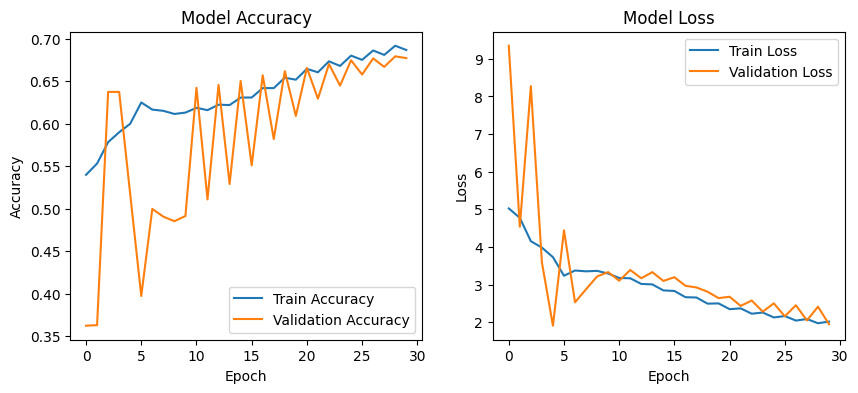

In [28]:
# Model accuracy
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Model loss
plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

For model validation accuracy, the learning curve for the baseline model indicates that training accuracy increases gradually over time, while validation accuracy fluctuates noticeably across epochs

For model validation loss, the learning curve shows that training loss steadily decreases over time as the model learns from the training data, while validation loss decreases overall while exhibiting some fluctuations across epochs.

This suggests that although the model is able to learn patterns from the training dataset, its performance on unseen validation data is inconsistent. The fluctuations in validation metrics indicate that the baseline model may have limited representational capacity, meaning it may not be sufficiently complex to capture all the relationships within the dataset. 

Overall, the baseline model provides a useful reference point for evaluating more complex neural network architectures. Although the model is able to learn basic patterns from the training data, the relatively modest validation accuracy and fluctuations in validation metrics suggest that the simple architecture may not be sufficiently expressive to capture more complex relationships within the dataset. Therefore, a more complex neural network with additional hidden layers will be explored in the next stage to improve predictive performance.

## 6. Developing a second model with Relu hidden layer

For the second model, a hidden layer with 32 neurons using the ReLU activation function is introduced to increase the representational capacity of the neural network. This allows the model to learn non-linear relationships between the input features and the target variable, which the baseline model may not capture effectively.

In addition, the optimizer has been changed to the Adam optimizer, which provides adaptive learning rates for each parameter. This enables the network to converge faster and more efficiently compared to standard stochastic gradient descent (SGD), while also improving training stability.

In [29]:
#RelU hidden layeer is added with 32 neurons
model2 = Sequential([
    Input(shape=(num_inputs,)),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

#instead of sgd, adam is used as its more effecient
model2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Similar to the baseline model, training will be performed for 30 epochs.

In [30]:
#Training the second model
history2 = model2.fit(
    X_tr,
    y_tr,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=256,
    verbose=0
)
print("The second model has now been trained.")

The second model has now been trained.


Similar to the baseline model, we use the validation dataset to detect potential underfitting and give us its validation accuracy and binary cross-entropy loss.

In [31]:
model2.evaluate(X_val, y_val)

282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 786us/step - accuracy: 0.9478 - loss: 0.1667


[0.16668085753917694, 0.9477777481079102]

After training the model and using evaluated using the validation dataset, the model achieved a validation accuracy of approximately 94.78%, with a binary cross-entropy loss of 0.1667.
Compared to the baseline model, it is a signicant improvement in predictive performance.

Next, lets analyze the learning curves of the second model to determine its training accuracy.

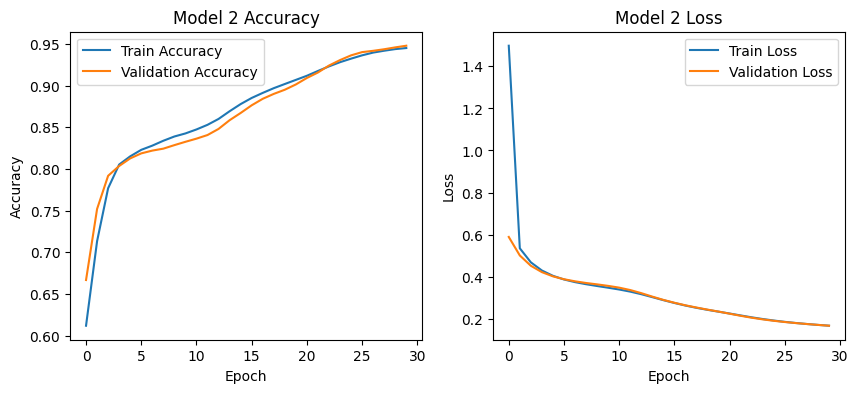

In [32]:
# Model 2 accuracy
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history2.history["accuracy"], label="Train Accuracy")
plt.plot(history2.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model 2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Model 2 loss
plt.subplot(1,2,2)
plt.plot(history2.history["loss"], label="Train Loss")
plt.plot(history2.history["val_loss"], label="Validation Loss")
plt.title("Model 2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

For validation accuracy, both the training and validation accuracy curves increase rapidly during the early epochs and gradually stabilise as training progresses. This indicates that the model quickly learns meaningful patterns from the dataset and continues to improve before reaching convergence.

For validation loss, both the training and validation loss decrease steadily across epochs, suggesting that the optimisation process is stable and the model continues to improve as training progresses.

The close alignment between the training and validation curves indicates that the model generalises well to unseen data and does not exhibit significant overfitting.

This improved performance can be attributed to the addition of the hidden layer with ReLU activation, which increases the representational capacity of the neural network and allows it to learn non-linear relationships between the input features and the placement outcome.

Overall, the second model demonstrates a clear improvement over the baseline model. However, further experimentation with additional layers or regularisation techniques may be explored to further enhance model performance.

## 7.1 Developing a Third Model with Additional ReLU Hidden Layers and Dropout

For the third model, an additional ReLU hidden layer with 64 neurons and dropout regularisation are introduced to increase the model’s representational capacity. Dropout helps reduce overfitting by randomly deactivating a proportion of neurons during training, which discourages the network from relying on a small subset of features and improves generalisation to unseen data.

In [33]:
model3 = Sequential([
    Input(shape=(num_inputs,)),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Training for the third model is performed for 80 epochs. Since the model architecture is deeper and includes dropout regularisation, more epochs are required to allow the network sufficient time to learn meaningful patterns from the data. Dropout randomly deactivates neurons during training, which slows down convergence but helps improve generalisation. Increasing the number of epochs therefore allows the model to stabilise and reach better performance while reducing the risk of overfitting.

In [34]:
history3 = model3.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=80,    
    batch_size=256,
    verbose=0
)
print("The third model has now been trained.")

The third model has now been trained.


In [35]:
model3.evaluate(X_val, y_val)

282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 764us/step - accuracy: 0.9884 - loss: 0.0280


[0.028006868436932564, 0.988444447517395]

After training the model and using evaluated using the validation dataset, the model achieved a validation accuracy of approximately 98.84%, with a binary cross-entropy loss of 0.0280. Comparing it to the second model, it is a signicant improvement in predictive performance. 

Next, lets analyze the learning curves of third model to determine its training accuracy.

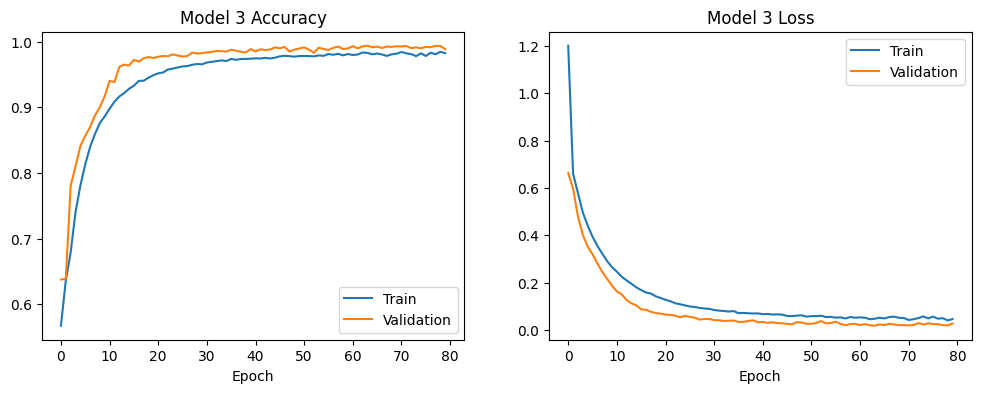

In [36]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history3.history['accuracy'], label='Train')
plt.plot(history3.history['val_accuracy'], label='Validation')
plt.title("Model 3 Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history3.history['loss'], label='Train')
plt.plot(history3.history['val_loss'], label='Validation')
plt.title("Model 3 Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

Similar to the second model, both the training and validation accuracy curves increase rapidly during the early epochs and gradually stabilise as training progresses. This indicates that the model quickly learns meaningful patterns from the dataset and reaches convergence after sufficient training.

For validation loss, both the training and validation loss decrease steadily across epochs, suggesting that the optimisation process remains stable throughout training.

Compared to the second model, the third model achieves slightly higher validation accuracy and lower loss, indicating a small improvement in predictive performance.

This improvement can be attributed to the addition of an extra hidden layer and dropout regularisation, which increases the representational capacity of the neural network while helping to reduce potential overfitting. The dropout layers encourage the network to learn more robust feature representations by preventing it from relying too heavily on specific neurons.

Overall, the progression from the baseline model to the second and third models demonstrates that increasing the depth of the neural network and introducing regularisation techniques can significantly improve predictive performance. The baseline model provided a useful reference point but showed limited ability to capture complex relationships in the dataset. By introducing a hidden layer with ReLU activation, the second model was able to learn more complex non-linear patterns, resulting in a substantial improvement in validation accuracy. Finally, the third model further enhanced performance through the addition of another hidden layer and dropout regularisation, which increased representational capacity while helping to prevent overfitting. As a result, the third model achieved the best overall performance with the highest validation accuracy and lowest validation loss, indicating strong generalisation to unseen data.

## 7.2 Model Comparison

Lets review our valiation loss and valiation accuracy for the 3 models.

| Model | Architecture | Validation Loss | Validation Accuracy |
|------|-------------|----------------|--------------------|
| Base Model  (Baseline) | Dense(1) | 1.9478| 67.73% |
| Model 2 (Hidden Layer) | Dense(32) → Dense(1) | 0.1667 | 94.78 % |
| Model 3 (Regularised) | Dense(64) → Dropout → Dense(32) → Dropout → Dense(1) | 0.0280 | 98.84% |

By comparing the three models, it can be observed that there is a clear improvement in predictive performance as the neural network architecture becomes more complex.

The baseline model, which contains only a single dense output layer and uses the SGD optimizer, achieved a validation accuracy of 67.73% with a validation loss of 1.9478. This indicates that the simple architecture has limited capacity and is unable to capture the relationships within the dataset effectively.

The second model introduces a hidden layer with ReLU activation, which significantly improves performance. The model achieved a validation accuracy of 94.78% while substantially reducing the validation loss. This improvement shows that the addition of hidden layers enables the neural network to learn more complex non-linear relationships between the input features and the placement outcome.

Finally, the third model introduces an additional ReLU hidden layer together with dropout regularisation, achieving the highest validation accuracy of 98.84% and the lowest validation loss of 0.0280. The dropout layers help reduce overfitting by preventing the network from relying too heavily on specific neurons and encouraging it to learn more robust feature representations.

Overall, Model 3 provides the best balance between model complexity and generalisation performance, achieving the highest predictive accuracy while maintaining low validation loss.

## 7.3 Final Test Evaluation

Now we have evaluated our best model, we shall apply our model on the test dataset in order to estimate its performance on completely unseen data. 

In [37]:
model3.evaluate(Xtest, ytest)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 811us/step - accuracy: 0.9880 - loss: 0.0287


[0.028723174706101418, 0.9879999756813049]

The model achieved a test accuracy of 98.80% with a test loss of 0.0287, indicating excellent predictive performance. The test accuracy is very similar to the recorded validation accuracy, suggesting that the model generalises well and does not suffer from significant overfitting.

These results confirm that the architecture and regularisation strategy used in Model 3 are effective for this dataset. The combination of additional hidden layers and dropout regularisation enables the model to capture complex relationships in the data while maintaining strong generalisation capability.

## 8. Conclusion

In conclusion, this project explored the development of neural network models to predict student placement outcomes using progressively more complex architectures. Starting with a simple baseline model, additional hidden layers and activation functions were introduced to increase the model's representational capacity. The results show that increasing the depth of the neural network significantly improved predictive performance. The baseline model achieved relatively low accuracy, while the introduction of hidden layers in Model 2 enabled the network to capture more complex non-linear relationships within the dataset. Model 3 further improved performance by incorporating an additional hidden layer and dropout regularisation, which helped improve generalisation and reduce potential overfitting. The final model achieved a validation accuracy of approximately 98.84% and a test accuracy of 98.80%, demonstrating strong predictive performance on unseen data. Overall, the experiment highlights the importance of model architecture design and regularisation techniques in improving neural network performance for classification tasks.

## 9. Key Takeaways

### Decision Framework Summary

| Decision | Threshold | This Dataset | Choice |
|----------|-----------|--------------|--------|
| **Hold-Out vs K-Fold** | > 10,000 samples | 50,000 samples | Hold-Out |
| **Accuracy vs F1-Score** | 1.5:1 – 3:1 imbalance | 1.76:1 ratio | Accuracy |




### Technique Scope 

| Technique | Status | Rationale |
|-----------|--------|-----------|
| **Dense layers (MLP/DNN)** | ✓ Used | Core building block (Ch. 3-4) |
| **Dropout** | ✓ Used | Regularisation technique (Ch. 4) |

### Lessons Learned

1. **Increasing model complexity significantly improves performance:** The baseline model with only a single dense output layer performed poorly, achieving relatively low validation accuracy. This demonstrates that a simple model does not have sufficient capacity to capture the relationships between the input features and the placement outcome.

2. **Hidden layers enable the network to learn non-linear relationships:** The introduction of a hidden layer in Model 2 with ReLU activation significantly improved predictive performance. This demonstrates that neural networks benefit from hidden layers that allow them to learn more complex patterns within the dataset.

3. **Regularisation helps improve generalisation:** The introduction of dropout layers in Model 3 helped reduce the risk of overfitting by preventing the network from relying too heavily on specific neurons. This encourages the model to learn more robust feature representations and improves its ability to generalise to unseen data.
   
4. **Model architecture has a major impact on performance:** The comparison between the three models demonstrates that careful architecture design plays a critical role in neural network performance. Increasing the depth of the network and introducing regularisation resulted in substantial improvements in both accuracy and loss.

## 10. References

### References 

[1] Kaggle Dataset, last accessed March 2026. https://www.kaggle.com/datasets/sonalshinde123/student-placement-dataset

[2] Branco, P., Torgo, L. and Ribeiro, R.P. (2016) 'A survey of predictive modelling on imbalanced domains', *ACM Computing Surveys*, 49(2), pp. 1–50.

[3] He, H. and Garcia, E.A. (2009) 'Learning from imbalanced data', *IEEE Transactions on Knowledge and Data Engineering*, 21(9), pp. 1263–1284.

[4] Hastie, T., Tibshirani, R. and Friedman, J. (2009) The Elements of Statistical Learning. 2nd ed. Springer.

[5] urphy, K.P. (2012) Machine Learning: A Probabilistic Perspective. MIT Press.

